# OCR evaluation: colleague run, 134 labeled images

This notebook reproduces the current report from `input/ocr_all_results.json` (uploaded as `ocr_all_results(1).json`) and the newly supplied `input/ocr_labels.txt`.

**The new label file is the sole source of reference text and marking categories.** Earlier image numbering, labels, and crop overrides are not used. All 134 image names match one label. The supplied labels classify 65 images as Engrave and 69 as Laser Mark.

Open this notebook from the extracted `ocr_eda` folder with Python and matplotlib installed. Run cells in order. No network requests or OCR model inference are performed.


In [1]:
from pathlib import Path
import json, csv, runpy
from IPython.display import display, HTML, Image
base=Path.cwd()
assert (base/'analysis.py').is_file(), 'Open from the extracted ocr_eda folder'
with (base/'../labels/ocr_labels.txt').open(encoding='utf-8-sig',newline='') as f:
    labels=list(csv.DictReader(f,delimiter=';'))
print('New human reference rows:',len(labels))
print('Categories:',sorted({r['Category'] for r in labels}))

New human reference rows: 134
Categories: ['Engrave', 'Laser Mark']


## Recompute and audit

`analysis.py` validates unique label/image keys, exact label coverage, nonempty references, and two profiles per image. It calculates raw and normalized Levenshtein CER and whole-transcription exact match.

Normalization removes whitespace and uppercases text, preserving punctuation, leading zeros, and O/0 distinctions. It does not reorder text. Raw scoring preserves label whitespace, including one trailing space in `ocr_test_025`.

Mean CER gives each image equal weight; pooled CER weights reference character counts. Wilson intervals for exact match assume independent observations and do not establish production representativeness.


In [2]:
analysis=runpy.run_path(str(r'./analysis.py'))

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\jchurt\\image-ocr\\CHAT_GPT_EDA\\input\\ocr_labels.txt'

## Overall results

Model,Normalized exact,95% interval,Mean CER,Pooled CER,Mean / median / P95 seconds
EasyOCR,50/134 (37.3%),29.6%–45.7%,21.8%,21.3%,0.90 / 0.42 / 3.12
Florence-2,90/134 (67.2%),58.8%–74.5%,5.4%,4.2%,8.90 / 8.77 / 10.08


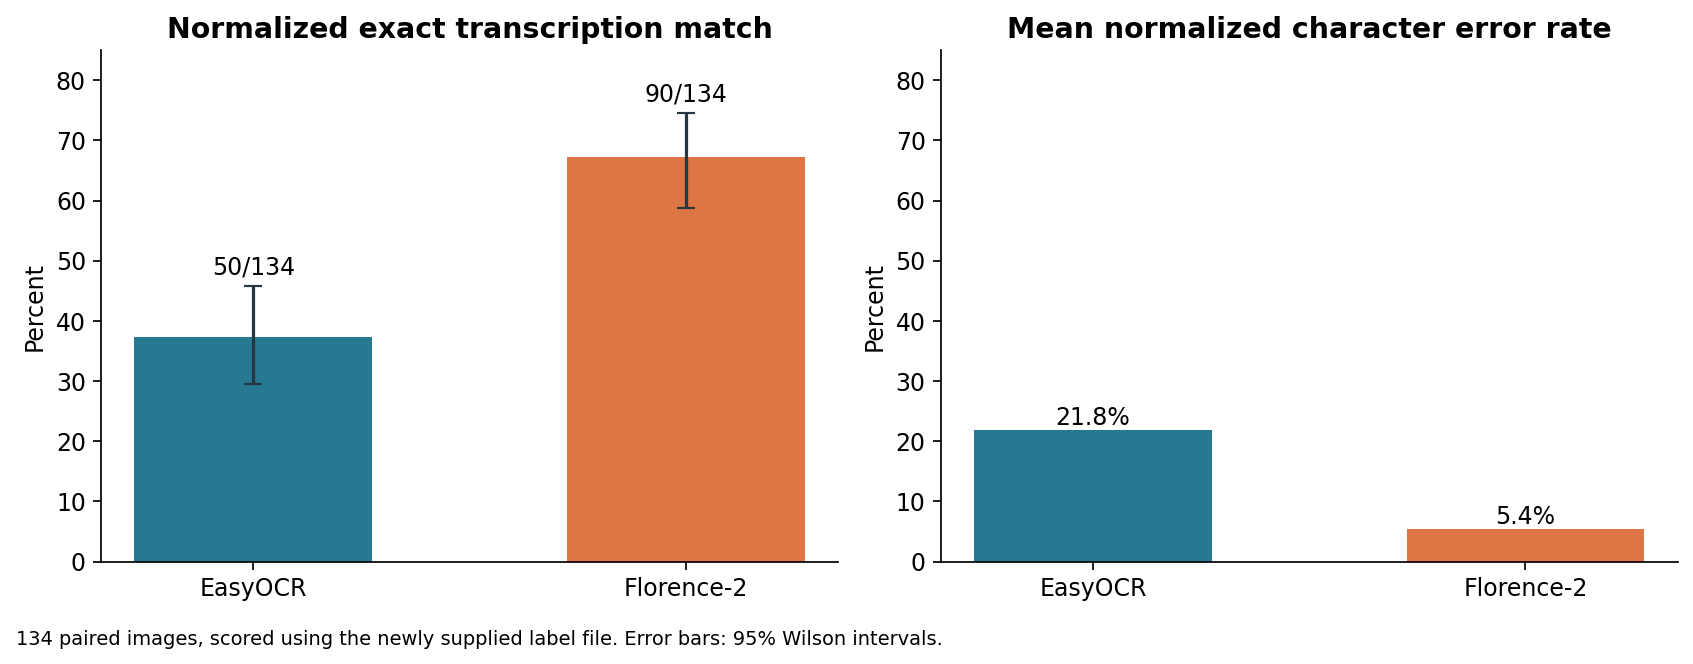

In [ ]:
display(HTML(analysis['summary_table'](analysis['overall'])))
display(Image(filename=str(base/'results/overall.png')))

## Marking-type results

Only Engrave and Laser Mark appear in the new reference file. No earlier marking labels are carried over.

Category,Images,EasyOCR exact,Florence-2 exact,EasyOCR mean CER,Florence-2 mean CER
Engrave,65,21/65 (32.3%),45/65 (69.2%),25.8%,6.6%
Laser Mark,69,29/69 (42.0%),45/69 (65.2%),18.1%,4.2%


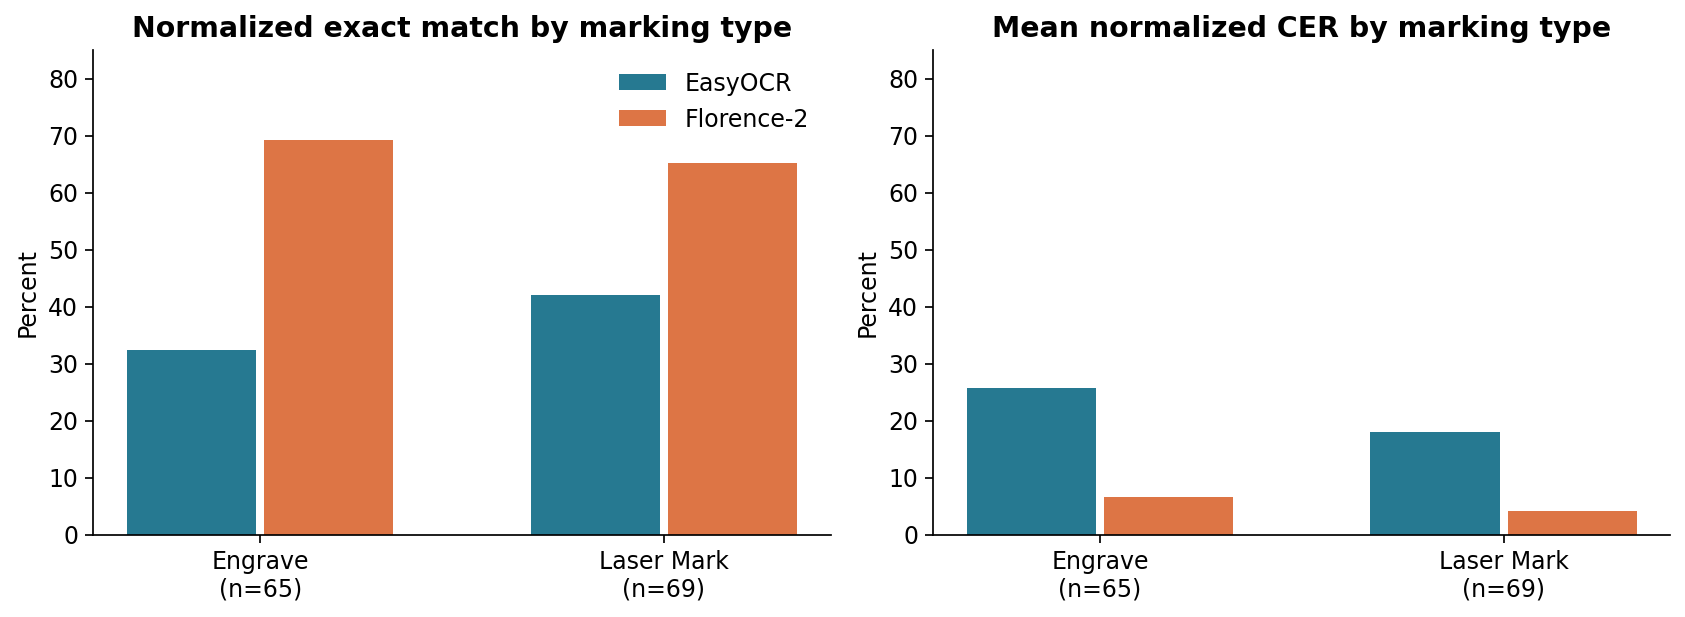

In [ ]:
display(HTML(analysis['category_table']))
display(Image(filename=str(base/'results/categories.png')))

## Distributions and paired outcomes

CER above 100% can occur with inserted characters and is retained. Processing excludes startup; the total-time field includes recorded startup overhead. These are observations from one supplied run.

Paired exact outcomes (EasyOCR, Florence-2): {(0, 1): 51, (1, 1): 39, (0, 0): 33, (1, 0): 11}
Normalized output agreements: 42
Agreements matching human truth: 39


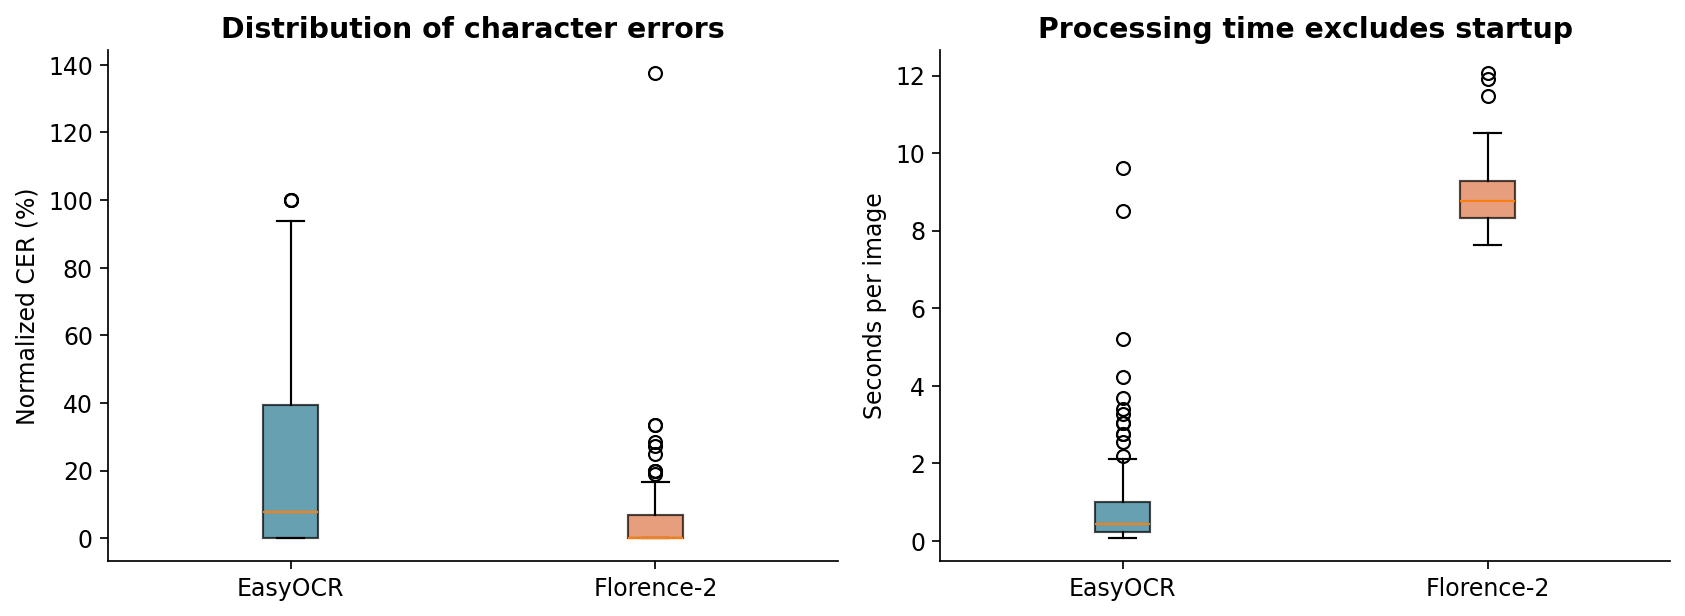

In [ ]:
display(Image(filename=str(base/'results/distributions.png')))
print('Paired exact outcomes (EasyOCR, Florence-2):',dict(analysis['outcomes']))
print('Normalized output agreements:',len(analysis['agree']))
print('Agreements matching human truth:',analysis['agree_correct'])

## Examples for review

Review both large errors and near matches against source images. Low CER still permits an incorrect part ID. Model agreement is not ground truth.

In [ ]:
display(HTML(analysis['worst']))
display(HTML(analysis['near_table']))
image_id='ocr_test_016'
for r in analysis['rows']:
    if r['image']==image_id:
        print(r['profile'],'truth:',repr(r['truth_text']),'prediction:',repr(r['ocr_text']),'CER:',r['normalized_cer'])

baseline truth: 'T-5914 THIS SIDE OUT' prediction: 'ThIS  SIDE\n\nOUT\n\n15914' CER: 0.6470588235294118
large truth: 'T-5914 THIS SIDE OUT' prediction: 'T-5914 THIS SIDE OUT' CER: 0.0


Image,Category,Human reference,Florence-2 output,Normalized CER
ocr_test_122,Engrave,20918645,5010.8.0.0/5.0,137.5%
ocr_test_048,Engrave,209108,20981028,33.3%
ocr_test_065,Engrave,000744 372,007044 3712,33.3%
ocr_test_034,Laser Mark,XYZ-658,XYZ-658-0,28.6%
ocr_test_026,Laser Mark,10.4 mm 90 HSS,10.4 mm 00-9ss,27.3%
ocr_test_043,Laser Mark,J261,J261.,25.0%


Image,Human reference,Florence-2 output,Normalized CER
ocr_test_031,012WA137 2/10/2024-C0023-VC,012WA137 02/10/2024-C0023-VC,3.8%
ocr_test_058,HA4104S156-M1 Q302EMC2,HA41045156-M1 Q302EMC2,4.8%
ocr_test_019,MFG DATE 10/21/2022,MFG DATE: 10/21/2022,5.9%
ocr_test_110,38010133 012 BLM099,38010133 012 BLM0999,5.9%
ocr_test_040,(P)1093278-00-B (S)ACP230865014510,(P)10932278-00-B (S)ACP2308665014510,6.1%


## Interpretation and next experiments

- These are complete reference-transcription scores; evaluate isolated target IDs and assembly-slot placement separately.
- Review wrong agreements and near matches before defining automatic acceptance.
- Add RapidOCR on the same images and references.
- Evaluate capture lighting and cropping on development data, then use held-out physical parts for final evaluation.
- Report wrong accepts, review workload, and whole-assembly accuracy for the deployment task.

Earlier 71- and 140-image results involve different populations and references and are not directly comparable as model-improvement measurements.

Open `results/OCR_EDA_Report.html` for the report. Scored rows, paired predictions, category/overall summaries, and `audit.json` are also in `results/`.
